In [222]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE
from sklearn.metrics import confusion_matrix, accuracy_score, roc_auc_score, roc_curve, precision_score, recall_score

In [223]:
df = pd.read_csv("Titanic.csv")

In [224]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [225]:
column_names = ["No._of_passengers", "Survived", "Pclass", "Name", "Sex", "Age", "Siblings", "Parch",	"Ticket", "Fare", "Cabin",	"Embarked"]

In [226]:
df.columns = column_names

In [227]:
df.head()

,No._of_passengers,Survived,Pclass,Name,Sex,Age,Siblings,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [228]:
from sklearn.preprocessing import LabelEncoder, StandardScaler

In [229]:
le_sex = LabelEncoder()
le_Embarked = LabelEncoder()
df["Sex"] = le_sex.fit_transform(df["Sex"])
df["Embarked"] = le_Embarked.fit_transform(df["Embarked"])

In [230]:
df.head()

,No._of_passengers,Survived,Pclass,Name,Sex,Age,Siblings,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",1,34.5,0,0,330911,7.8292,NaN,1
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",0,47.0,1,0,363272,7.0000,NaN,2
2,894,0,2,"Myles, Mr. Thomas Francis",1,62.0,0,0,240276,9.6875,NaN,1
3,895,0,3,"Wirz, Mr. Albert",1,27.0,0,0,315154,8.6625,NaN,2
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",0,22.0,1,1,3101298,12.2875,NaN,2


In [231]:
df.isnull().sum()

No._of_passengers      0
Survived               0
Pclass                 0
Name                   0
Sex                    0
Age                   86
Siblings               0
Parch                  0
Ticket                 0
Fare                   1
Cabin                327
Embarked               0
dtype: int64

In [232]:
print(df["Age"].median())

27.0


In [233]:
df["Age"] = df["Age"].fillna(df["Age"].median())

In [234]:
df.isnull().sum()

No._of_passengers      0
Survived               0
Pclass                 0
Name                   0
Sex                    0
Age                    0
Siblings               0
Parch                  0
Ticket                 0
Fare                   1
Cabin                327
Embarked               0
dtype: int64

In [235]:
print(df["Fare"].median())

14.4542


In [236]:
df["Fare"] = df["Fare"].fillna(df["Fare"].median())

In [237]:
df["Fare"].isnull().sum()

np.int64(0)

In [238]:
x= df[["Pclass", "Sex", "Age", "Siblings", "Parch", "Fare", "Embarked"]]
y= df["Survived"]

In [239]:
x.isnull().sum()

Pclass      0
Sex         0
Age         0
Siblings    0
Parch       0
Fare        0
Embarked    0
dtype: int64

In [240]:
df.shape

(418, 12)

In [241]:
x.shape , y.shape

((418, 7), (418,))

In [242]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 42)

In [243]:
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [244]:
model = LogisticRegression()
model.fit(x_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [245]:
y_test_pred = model.predict(x_test)

In [246]:
y_test_pred_proba = model.predict_proba(x_test)[:, 1]

In [247]:
test_accuracy = accuracy_score (y_test, y_test_pred)
test_accuracy 

1.0

In [248]:
cm= confusion_matrix(y_test, y_test_pred)
cm

array([[50,  0],
       [ 0, 34]])

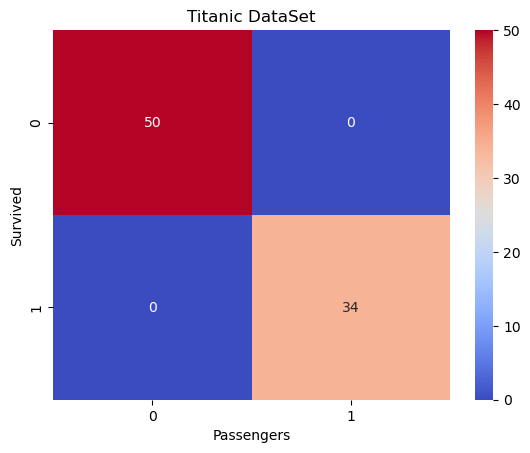

In [257]:
sns.heatmap(cm, annot = True, fmt = 'd', cmap = "coolwarm")
plt.xlabel("Passengers")
plt.ylabel("Survived")
plt.title("Titanic DataSet")
plt.show()

In [249]:
auc = roc_auc_score(y_test, y_test_pred_proba)
auc

1.0

In [250]:
fpr, tpr, threshold = roc_curve(y_test, y_test_pred_proba)

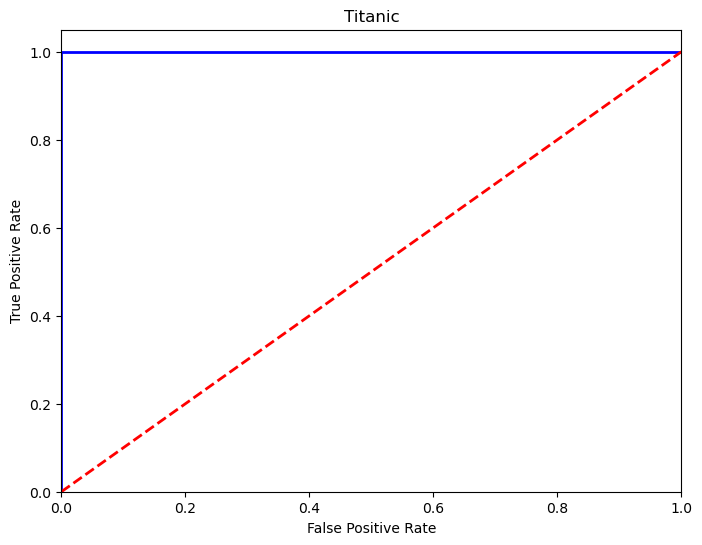

In [251]:
plt.figure(figsize= (8,6))
plt.plot(fpr, tpr, color = "blue", lw = 2, label = (f" roc_curve{auc}"))
plt.plot([0,1], [0,1], color = "red", lw = 2, linestyle = "--", label = "RandomGuessing")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Titanic")
plt.show()

In [252]:
y_train_pred = model.predict(x_train)

In [253]:
train_accuracy = accuracy_score(y_train, y_train_pred)
train_accuracy

1.0

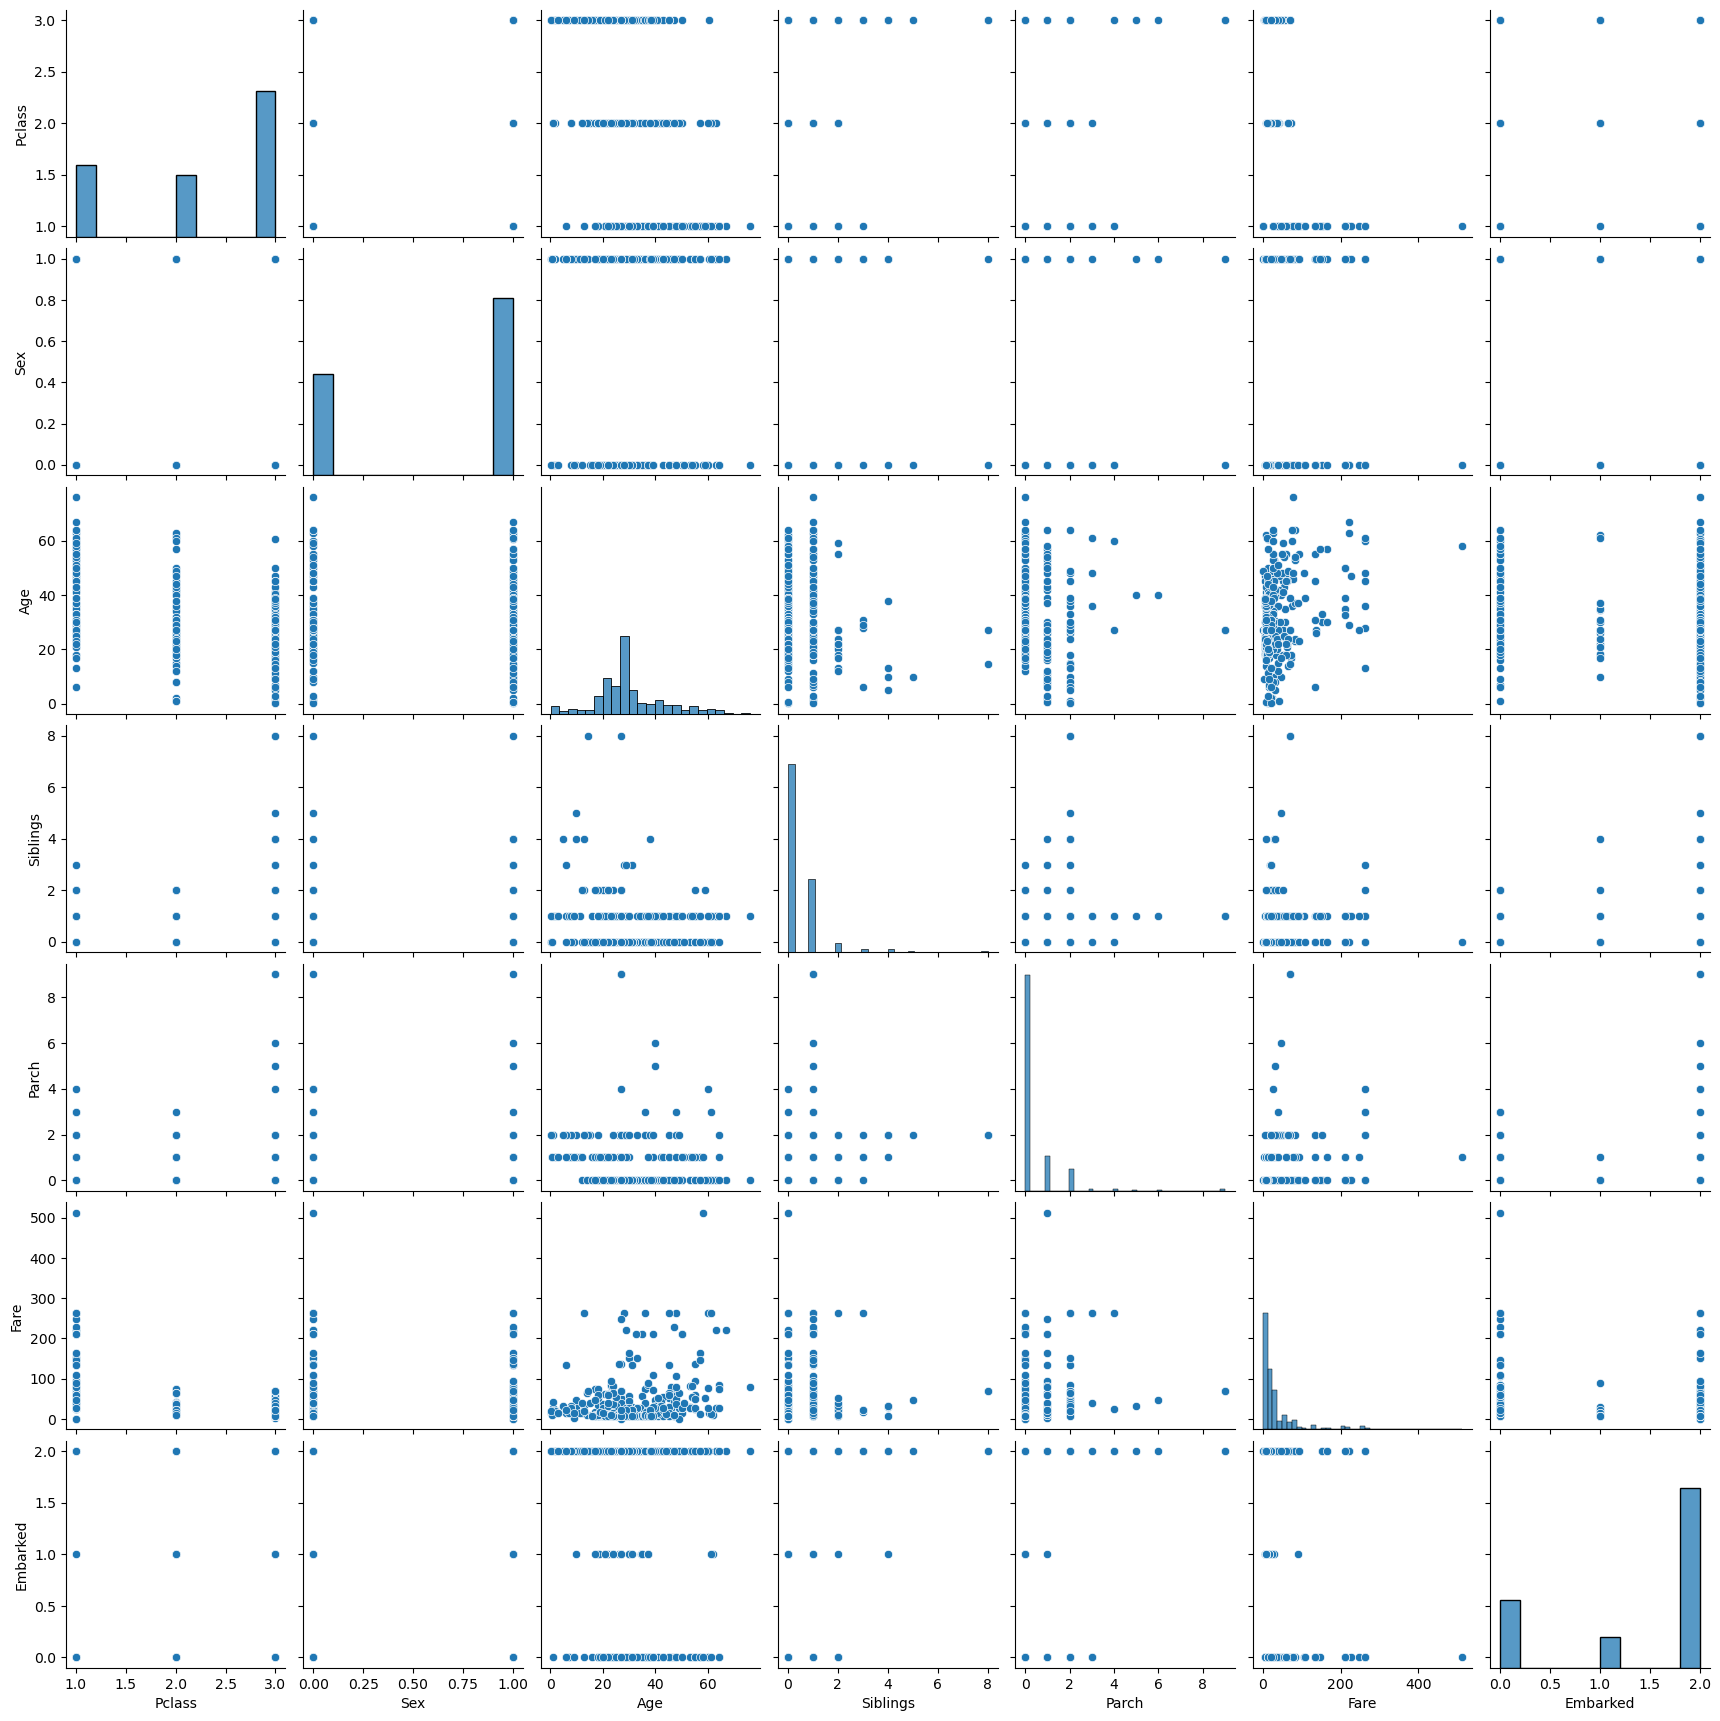

In [261]:
sns.pairplot(x)